In [4]:

# %% 0. Setup
import re, warnings
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

df = pd.concat([pd.read_csv(f'goemotions_{i}.csv') for i in (1, 2, 3)], ignore_index=True)

meta_cols = ['text', 'id', 'author', 'subreddit', 'link_id', 'parent_id',
             'created_utc', 'rater_id', 'example_very_unclear']
emotions = [c for c in df.columns if c not in meta_cols]

In [5]:

# Sentiment grouping from the GoEmotions paper
SENT = {
    'positive': ['admiration', 'amusement', 'approval', 'caring', 'desire', 'excitement',
                 'gratitude', 'joy', 'love', 'optimism', 'pride', 'relief'],
    'negative': ['anger', 'annoyance', 'disappointment', 'disapproval', 'disgust',
                 'embarrassment', 'fear', 'grief', 'nervousness', 'remorse', 'sadness'],
    'ambiguous': ['confusion', 'curiosity', 'realization', 'surprise'],
    'neutral': ['neutral'],
}
sent_of = {e: s for s, es in SENT.items() for e in es}
assert set(emotions) == set(sent_of), set(emotions) ^ set(sent_of)
emotions = [e for s in SENT for e in SENT[s]]          # order emotions by sentiment group
PAL = {'positive': '#4C9F70', 'negative': '#D1495B', 'ambiguous': '#EDAE49', 'neutral': '#8D99AE'}
emo_colors = [PAL[sent_of[e]] for e in emotions]


def barh_emotions(series, title, xlabel='', fmt=None):
    s = series.sort_values()
    plt.figure(figsize=(8, 8))
    plt.barh(s.index, s.values, color=[PAL[sent_of[e]] for e in s.index])
    plt.title(title); plt.xlabel(xlabel)
    if fmt:
        for i, v in enumerate(s.values):
            plt.text(v, i, fmt.format(v), va='center', fontsize=8)
    plt.tight_layout(); plt.show()

In [6]:

# %% 1. Data integrity
df['created_dt'] = pd.to_datetime(df['created_utc'], unit='s')
df['example_very_unclear'] = df['example_very_unclear'].astype(bool)
df['n_labels'] = df[emotions].sum(axis=1)

print('shape:', df.shape, '| emotions:', len(emotions))
print('labels strictly binary:', df[emotions].isin([0, 1]).all().all())
print('duplicate full rows      :', df.duplicated().sum())
print('duplicate (id, rater_id) :', df.duplicated(['id', 'rater_id']).sum())
print('ratings with 0 labels    :', f'{(df.n_labels == 0).mean():.2%}')
print('date range:', df.created_dt.min(), '->', df.created_dt.max())
print('unique comments / raters / authors / subreddits / threads:',
      df.id.nunique(), df.rater_id.nunique(), df.author.nunique(),
      df.subreddit.nunique(), df.link_id.nunique())
print('ids whose text differs between rows:', (df.groupby('id')['text'].nunique() > 1).sum())

print('\nRaters per comment:')
print(df.groupby('id').size().value_counts().sort_index())

shape: (211225, 39) | emotions: 28
labels strictly binary: True
duplicate full rows      : 0
duplicate (id, rater_id) : 0
ratings with 0 labels    : 1.61%
date range: 2019-01-01 00:00:19 -> 2019-01-31 23:59:36
unique comments / raters / authors / subreddits / threads: 58011 82 49178 483 44897
ids whose text differs between rows: 0

Raters per comment:
1       70
2      592
3    37335
4     2104
5    17910
Name: count, dtype: int64


comments: 58011 | with NO majority label: 6.46%
duplicate texts across different ids: 279


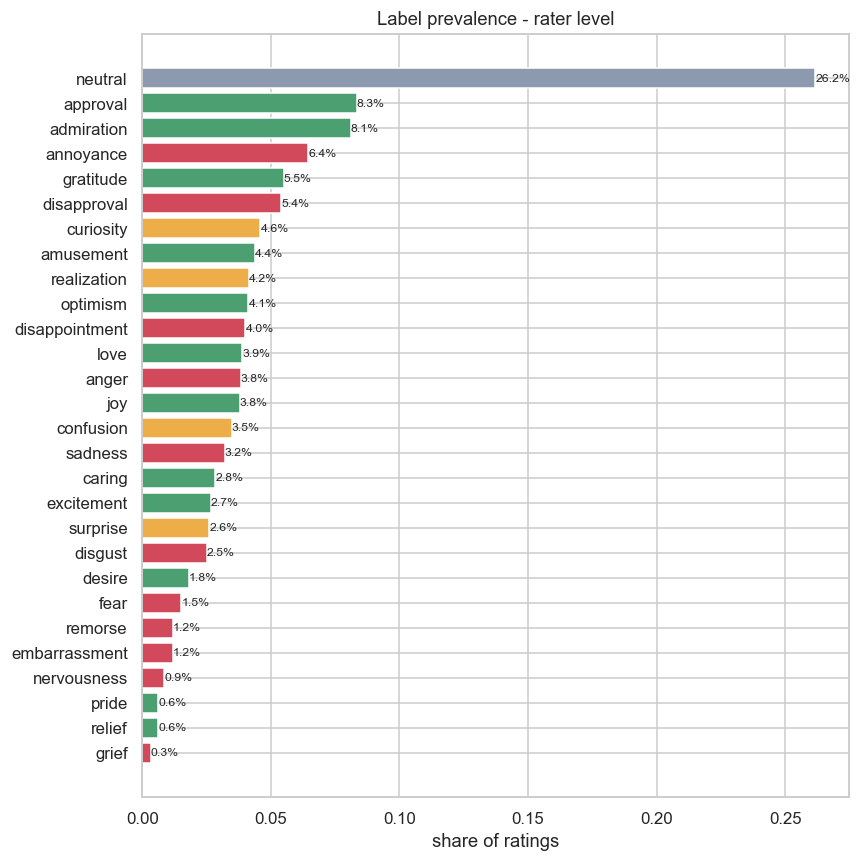

In [7]:

# %% 2. Build comment-level table (votes per emotion + majority labels)
g = df.groupby('id')
votes = g[emotions].sum()                                  # how many raters chose each emotion
C = (g.agg(text=('text', 'first'), author=('author', 'first'), subreddit=('subreddit', 'first'),
           link_id=('link_id', 'first'), parent_id=('parent_id', 'first'),
           created_dt=('created_dt', 'first'), n_raters=('rater_id', 'size'),
           unclear_frac=('example_very_unclear', 'mean'))
       .join(votes))
Y = (C[emotions] >= 2).astype(int)                         # majority label: >=2 raters agree (paper's rule)
C['n_major'] = Y.sum(axis=1)
print('comments:', len(C), '| with NO majority label:', f'{(C.n_major == 0).mean():.2%}')
print('duplicate texts across different ids:', C.text.duplicated().sum())

# %% 3. Label distribution
# 3a. Rating level (raw: every rater's vote)
rating_prev = df[emotions].mean()
barh_emotions(rating_prev, 'Label prevalence - rater level', 'share of ratings', '{:.1%}')

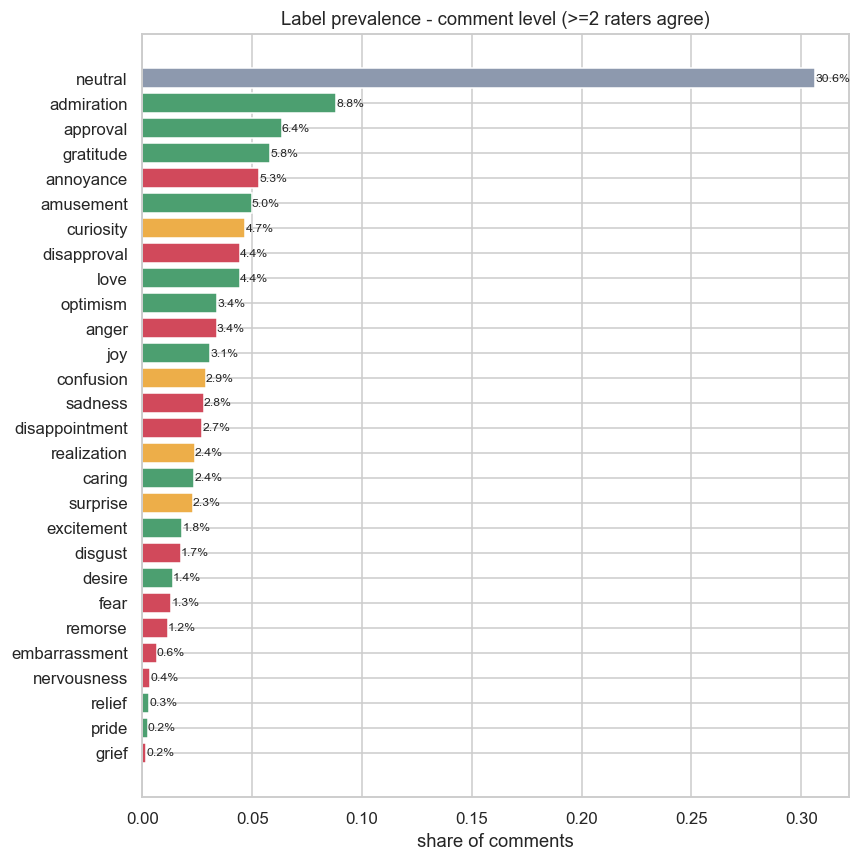

                rating_share  comment_share  comment_count  sentiment
neutral               0.2618         0.3064          17772    neutral
admiration            0.0811         0.0883           5122   positive
approval              0.0834         0.0636           3687   positive
gratitude             0.0550         0.0581           3372   positive
annoyance             0.0645         0.0533           3093   negative
amusement             0.0438         0.0499           2895   positive
curiosity             0.0459         0.0469           2723  ambiguous
disapproval           0.0541         0.0445           2581   negative
love                  0.0388         0.0444           2576   positive
optimism              0.0413         0.0341           1976   positive
anger                 0.0383         0.0338           1960   negative
joy                   0.0378         0.0308           1785   positive
confusion             0.0348         0.0288           1673  ambiguous
sadness             

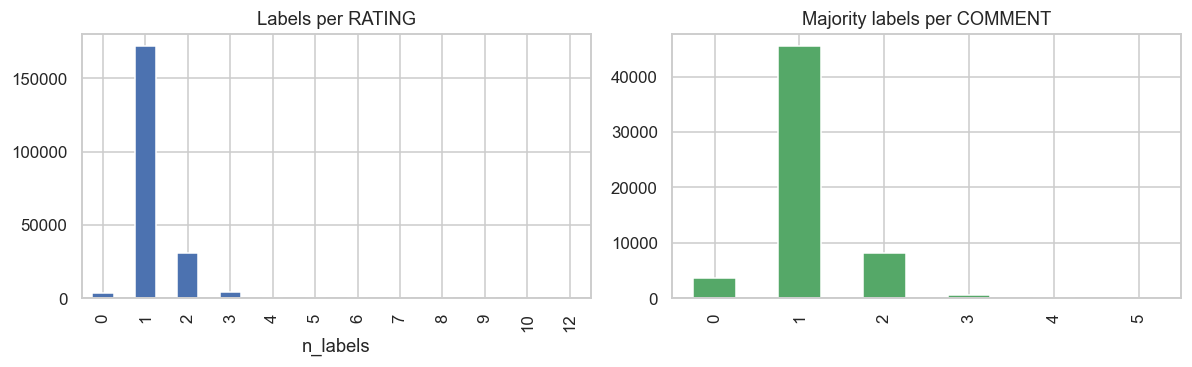

mean labels/rating: 1.181 | mean majority labels/comment: 1.1


In [8]:
# 3b. Comment level (majority vote)
cmt_prev = Y.mean()
barh_emotions(cmt_prev, 'Label prevalence - comment level (>=2 raters agree)', 'share of comments', '{:.1%}')

summary = pd.DataFrame({'rating_share': rating_prev, 'comment_share': cmt_prev,
                        'comment_count': Y.sum(), 'sentiment': pd.Series(sent_of)}).sort_values('comment_count', ascending=False)
print(summary.round(4))
print('\nImbalance ratio (max/min class):', round(summary.comment_count.max() / summary.comment_count.min(), 1))
print('Classes with <1% of comments:', list(summary.index[summary.comment_share < 0.01]))

# 3c. Label cardinality
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df.n_labels.value_counts().sort_index().plot.bar(ax=ax[0], color='#4C72B0'); ax[0].set_title('Labels per RATING')
Y.sum(axis=1).value_counts().sort_index().plot.bar(ax=ax[1], color='#55A868'); ax[1].set_title('Majority labels per COMMENT')
plt.tight_layout(); plt.show()
print('mean labels/rating:', df.n_labels.mean().round(3), '| mean majority labels/comment:', C.n_major.mean().round(3))

Top co-occurring pairs by lift (count>=50):
              a              b  count     lift
       remorse        sadness     71 3.788691
disappointment        sadness    163 3.675900
    excitement            joy    108 3.336416
         anger      annoyance    348 3.330072
     confusion      curiosity    253 3.221716
        desire       optimism     80 2.932114
        caring       optimism    106 2.263219
         anger        disgust     67 1.957581
     annoyance        disgust     99 1.832973
     annoyance disappointment    140 1.658737
     annoyance    disapproval    222 1.613227
     amusement            joy    110 1.234856
    admiration      gratitude    341 1.145348
     curiosity       surprise     69 1.105249
    admiration           love    236 1.037617

Most frequent pairs:
              a           b  count     lift
         anger   annoyance    348 3.330072
    admiration   gratitude    341 1.145348
    admiration    approval    298 0.915406
      approval     neutr

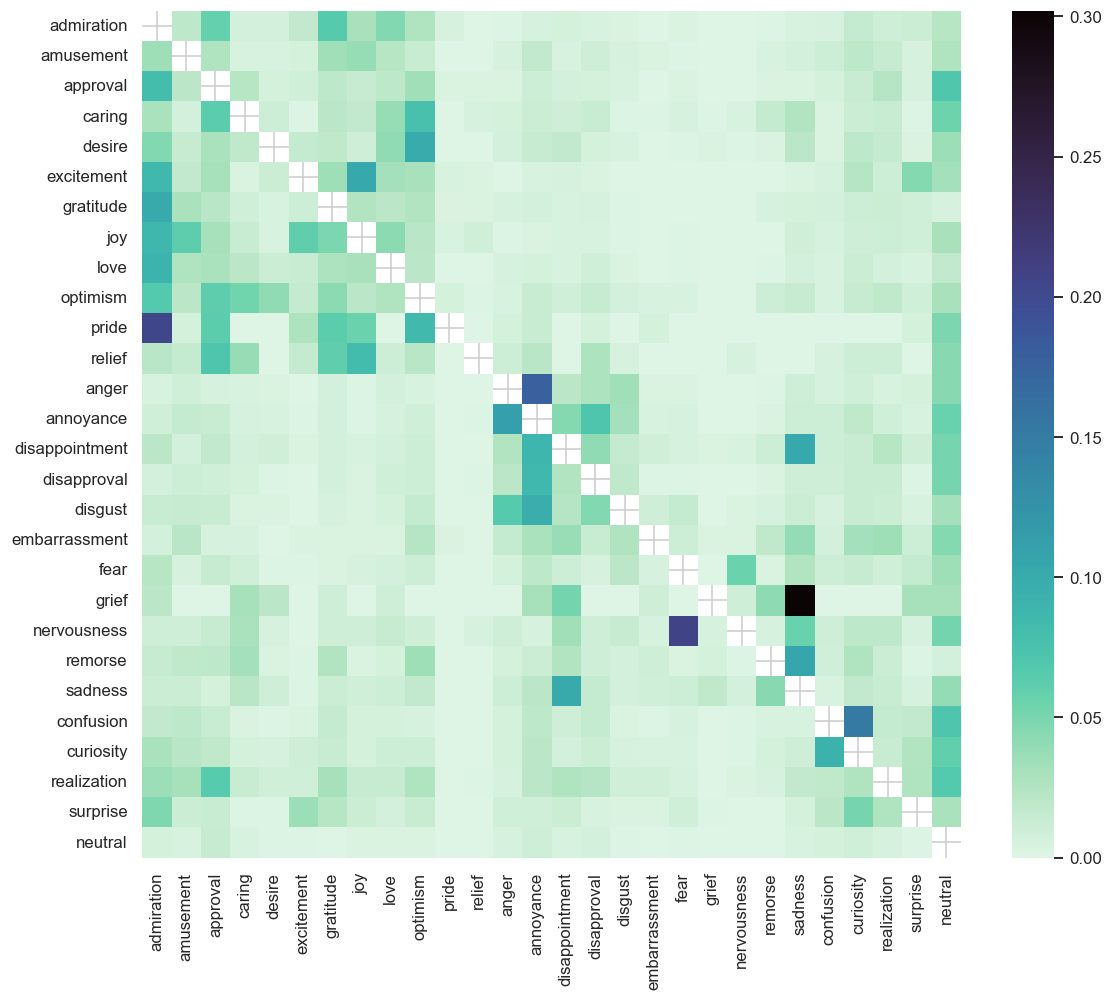

In [9]:
# %% 4. Label co-occurrence (comment level)
N = len(Y)
Cm = Y.T @ Y                                               # co-occurrence counts
cond = Cm.div(np.diag(Cm), axis=0)                         # P(column | row)
plt.figure(figsize=(12, 10))
sns.heatmap(cond, mask=np.eye(len(emotions), dtype=bool), cmap='mako_r', vmin=0, vmax=cond.where(~np.eye(28, dtype=bool)).max().max())
#plt.title('P(column emotion | row emotion) - majority labels'); plt.tight_layout(); plt.show()

P = np.diag(Cm) / N
rows = []
for i, j in combinations(range(len(emotions)), 2):
    c = Cm.iloc[i, j]
    if c >= 50:
        rows.append((emotions[i], emotions[j], c, (c / N) / (P[i] * P[j])))
pairs = pd.DataFrame(rows, columns=['a', 'b', 'count', 'lift']).sort_values('lift', ascending=False)
print('Top co-occurring pairs by lift (count>=50):\n', pairs.head(15).to_string(index=False))
print('\nMost frequent pairs:\n', pairs.sort_values('count', ascending=False).head(10).to_string(index=False))


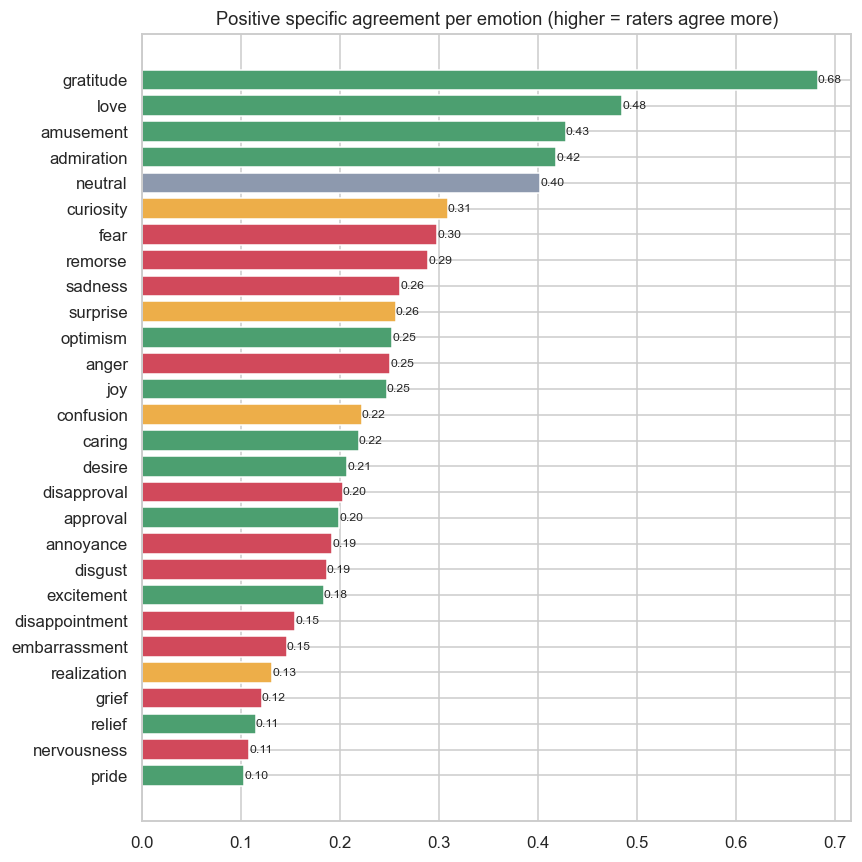

                pos_specific_agreement  confirmed_by_2nd_rater  comment_count
pride                            0.103                   0.126            142
nervousness                      0.108                   0.134            208
relief                           0.114                   0.168            182
grief                            0.121                   0.171             96
realization                      0.131                   0.191           1382
embarrassment                    0.146                   0.187            375
disappointment                   0.155                   0.238           1583
excitement                       0.183                   0.242           1052
disgust                          0.186                   0.250           1013
annoyance                        0.192                   0.308           3093
approval                         0.199                   0.278           3687
disapproval                      0.203                   0.307  

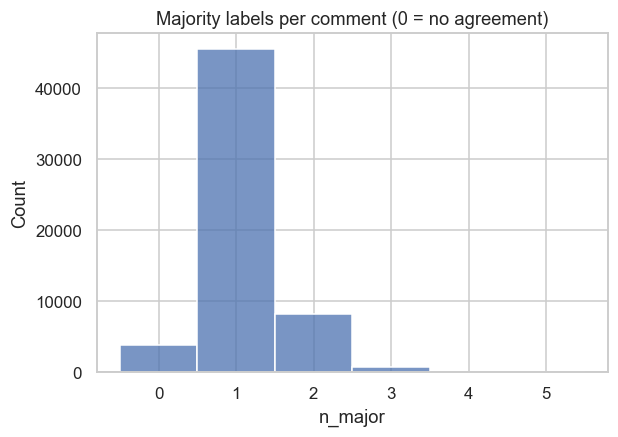

Share of comments with a single rater-agreed label: 78.34%
          comments  no_majority
n_raters                       
1               70        1.000
2              592        0.057
3            37335        0.011
4             2104        0.354
5            17910        0.140


In [10]:
# %% 5. Inter-rater agreement
k = votes.values.astype(float)
n = C['n_raters'].values[:, None].astype(float)
agree_pairs = (k * (k - 1) / 2).sum(axis=0)                # rater pairs that both chose emotion
disagree_pairs = (k * (n - k)).sum(axis=0)                 # pairs where only one chose it
psa = pd.Series(2 * agree_pairs / (2 * agree_pairs + disagree_pairs), index=emotions)   # positive specific agreement
confirm = pd.Series((k >= 2).sum(0) / np.maximum((k >= 1).sum(0), 1), index=emotions)   # P(>=2 raters | >=1 rater)

barh_emotions(psa, 'Positive specific agreement per emotion (higher = raters agree more)', '', '{:.2f}')
agree_tbl = pd.DataFrame({'pos_specific_agreement': psa, 'confirmed_by_2nd_rater': confirm,
                          'comment_count': Y.sum()}).sort_values('pos_specific_agreement')
print(agree_tbl.round(3))

plt.figure(figsize=(6, 4))
sns.histplot(C.n_major, discrete=True); plt.title('Majority labels per comment (0 = no agreement)'); plt.show()
print('Share of comments with a single rater-agreed label:', f'{(C.n_major == 1).mean():.2%}')
# agreement by number of raters
print(C.groupby('n_raters').agg(comments=('text', 'size'), no_majority=('n_major', lambda s: (s == 0).mean())).round(3))

               n  avg_labels  neutral_rate  unclear_rate  support
count     82.000      82.000        82.000        82.000   82.000
mean    2575.915       1.197         0.244         0.014    0.601
std     2306.272       0.263         0.144         0.029    0.088
min        1.000       0.890         0.000         0.000    0.369
25%      541.500       1.078         0.142         0.000    0.561
50%     2069.000       1.129         0.228         0.002    0.605
75%     4113.000       1.251         0.337         0.011    0.652
max    10508.000       3.111         0.746         0.126    1.000
Top-5 raters share of all ratings: 19.30%


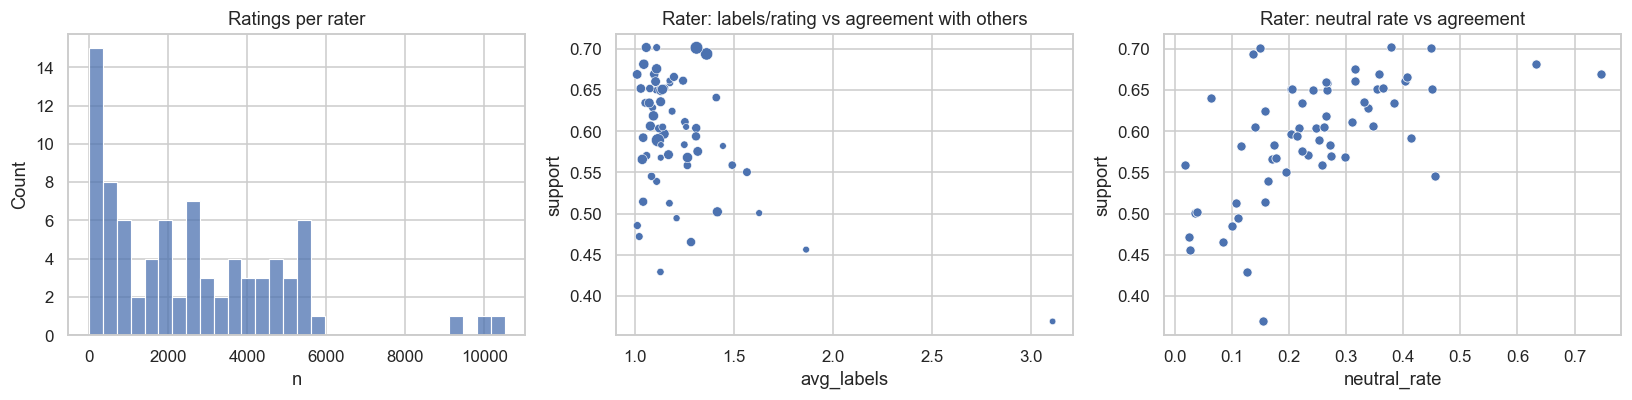

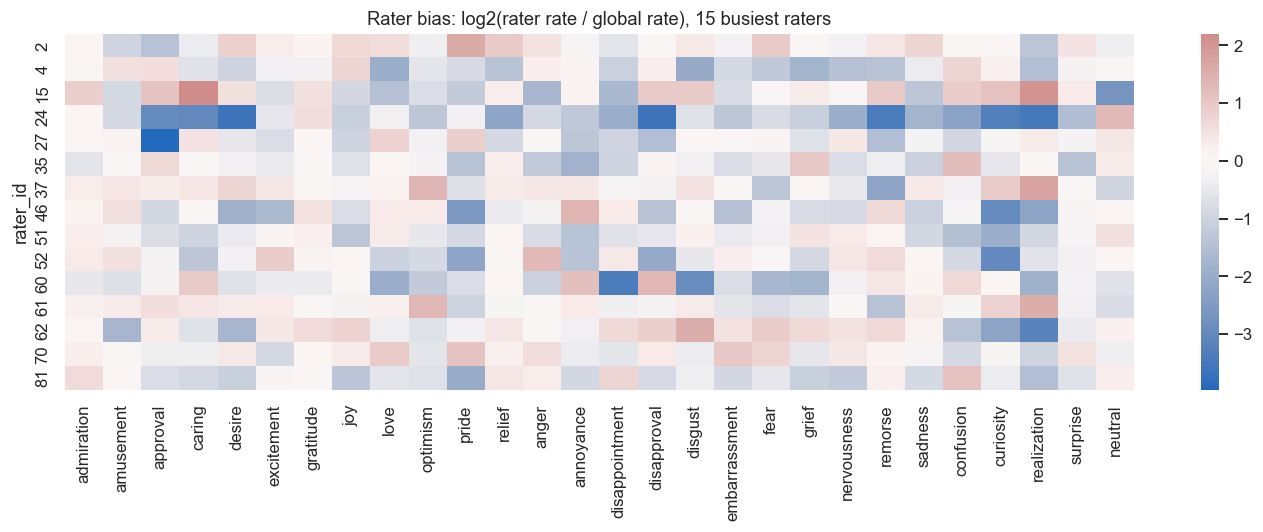

Least-agreeing busy raters:
              n  avg_labels  neutral_rate  unclear_rate  support
rater_id                                                       
31         576       3.111         0.155         0.002    0.369
7         1424       1.128         0.127         0.000    0.429
79         834       1.865         0.026         0.001    0.456
3         3767       1.282         0.085         0.010    0.465
11        1953       1.020         0.025         0.013    0.472


In [11]:
# %% 6. Raters
# for each rating: share of own labels that at least one OTHER rater also chose
own = df[emotions].values
others = votes.loc[df['id']].values - own
supported = ((own == 1) & (others >= 1)).sum(axis=1)
df['label_support'] = np.where(df.n_labels > 0, supported / df.n_labels.replace(0, np.nan), np.nan)

R = df.groupby('rater_id').agg(n=('id', 'size'), avg_labels=('n_labels', 'mean'),
                               neutral_rate=('neutral', 'mean'), unclear_rate=('example_very_unclear', 'mean'),
                               support=('label_support', 'mean'))
print(R.describe().round(3))
print('Top-5 raters share of all ratings:', f'{R.n.nlargest(5).sum() / R.n.sum():.2%}')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(R.n, bins=30, ax=ax[0]); ax[0].set_title('Ratings per rater')
big = R[R.n >= 500]
sns.scatterplot(data=big, x='avg_labels', y='support', size='n', ax=ax[1], legend=False)
ax[1].set_title('Rater: labels/rating vs agreement with others')
sns.scatterplot(data=big, x='neutral_rate', y='support', ax=ax[2]); ax[2].set_title('Rater: neutral rate vs agreement')
plt.tight_layout(); plt.show()

top = R.n.nlargest(15).index
prof = df[df.rater_id.isin(top)].groupby('rater_id')[emotions].mean()
plt.figure(figsize=(13, 5))
sns.heatmap(np.log2((prof + 1e-3) / (rating_prev + 1e-3)), cmap='vlag', center=0)
plt.title('Rater bias: log2(rater rate / global rate), 15 busiest raters'); plt.tight_layout(); plt.show()
print('Least-agreeing busy raters:\n', big.sort_values('support').head(5).round(3))

                count    mean     std  min     25%     50%     75%    max
n_chars       58011.0  68.824  36.626  2.0  38.000  66.000  96.000  703.0
n_words       58011.0  12.914   6.688  1.0   7.000  12.000  18.000   33.0
n_excl        58011.0   0.203   0.640  0.0   0.000   0.000   0.000   13.0
n_q           58011.0   0.121   0.394  0.0   0.000   0.000   0.000   10.0
caps_ratio    58011.0   0.062   0.113  0.0   0.023   0.038   0.062    1.0
has_name      58011.0   0.138   0.345  0.0   0.000   0.000   0.000    1.0
has_religion  58011.0   0.002   0.046  0.0   0.000   0.000   0.000    1.0
has_ellipsis  58011.0   0.055   0.227  0.0   0.000   0.000   0.000    1.0
has_url       58011.0   0.000   0.000  0.0   0.000   0.000   0.000    0.0
non_ascii     58011.0   0.243   2.153  0.0   0.000   0.000   0.000  475.0
texts <=2 words: 2.30% | >30 words: 0.01%


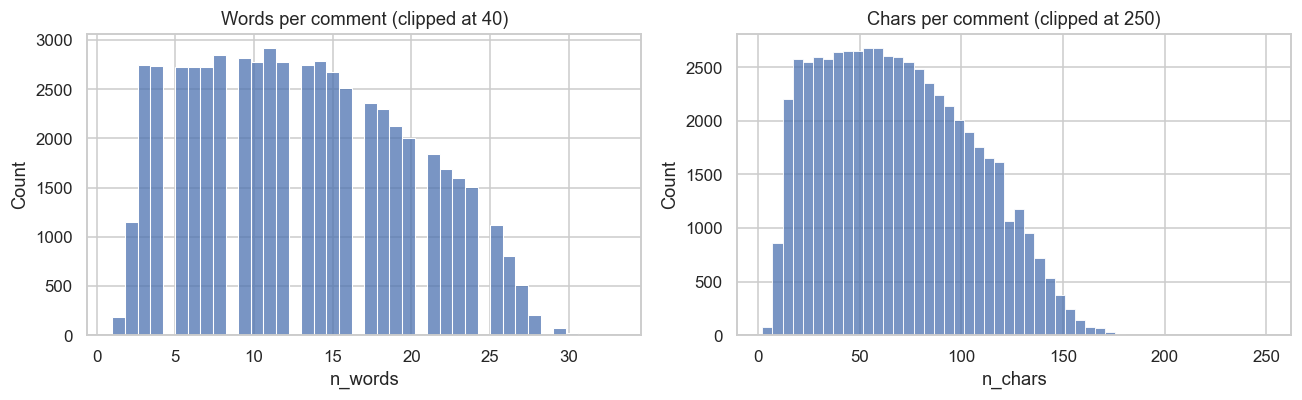

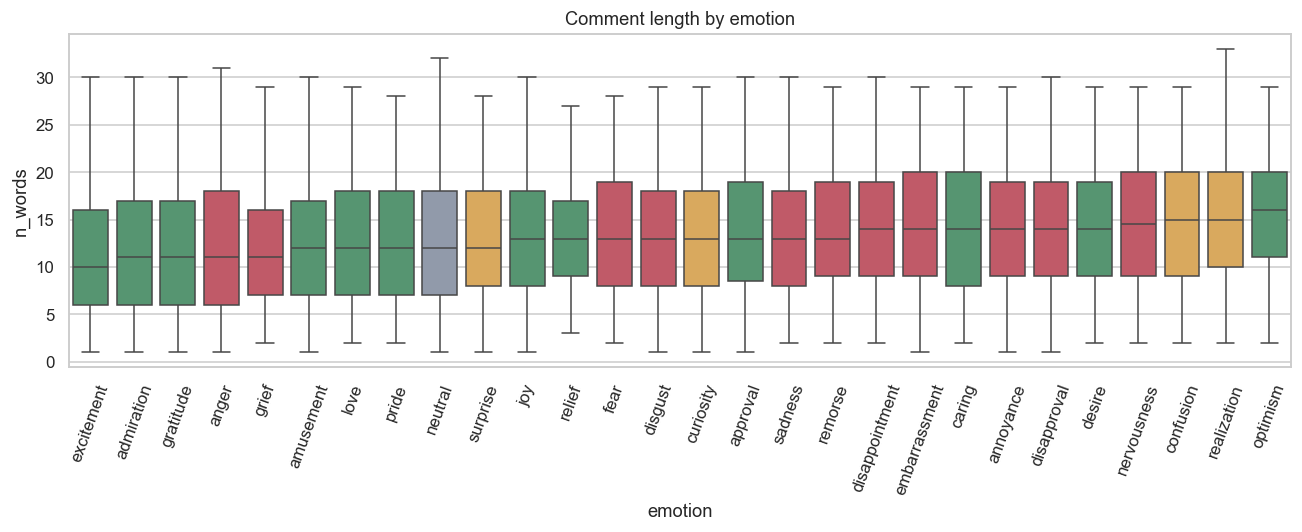

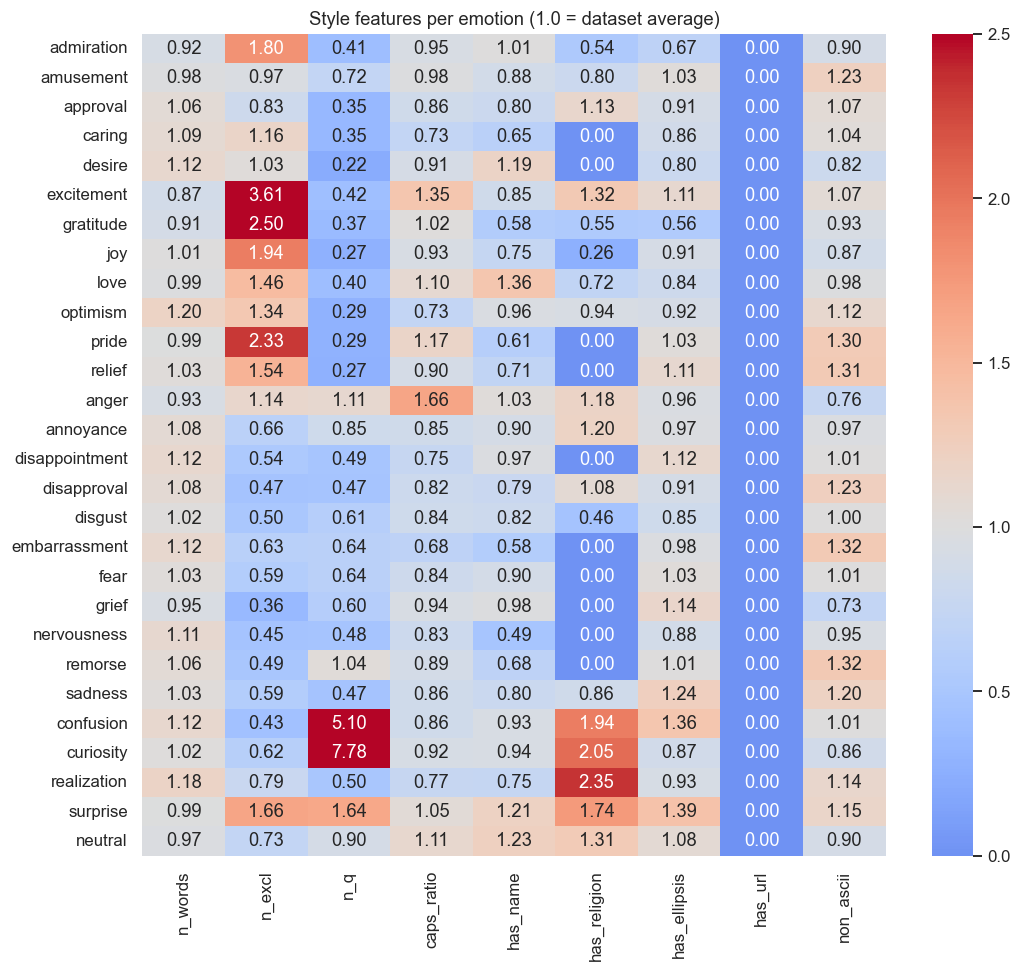

vocab size: 30699 | hapax words: 48.90% | tokens: 704967


In [12]:
# %% 7. Text characteristics (comment level)
def caps_ratio(s):
    s = re.sub(r'\[[A-Z]+\]', '', s)                       # ignore [NAME]/[RELIGION] masks
    letters = [c for c in s if c.isalpha()]
    return sum(c.isupper() for c in letters) / max(1, len(letters))

t = C['text']
C['n_chars'] = t.str.len()
C['n_words'] = t.str.split().str.len()
C['n_excl'] = t.str.count('!')
C['n_q'] = t.str.count(r'\?')
C['caps_ratio'] = t.apply(caps_ratio)
C['has_name'] = t.str.contains(r'\[NAME\]').astype(int)
C['has_religion'] = t.str.contains(r'\[RELIGION\]').astype(int)
C['has_ellipsis'] = t.str.contains(r'\.\.\.').astype(int)
C['has_url'] = t.str.contains('http').astype(int)
C['non_ascii'] = t.str.count(r'[^\x00-\x7f]')
feats = ['n_words', 'n_excl', 'n_q', 'caps_ratio', 'has_name', 'has_religion', 'has_ellipsis', 'has_url', 'non_ascii']
print(C[['n_chars', 'n_words'] + feats[1:]].describe().T.round(3))
print('texts <=2 words:', f'{(C.n_words <= 2).mean():.2%}', '| >30 words:', f'{(C.n_words > 30).mean():.2%}')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(C.n_words.clip(upper=40), bins=40, ax=ax[0]); ax[0].set_title('Words per comment (clipped at 40)')
sns.histplot(C.n_chars.clip(upper=250), bins=50, ax=ax[1]); ax[1].set_title('Chars per comment (clipped at 250)')
plt.tight_layout(); plt.show()

# length by emotion
long = pd.concat([C.loc[Y[e] == 1, ['n_words']].assign(emotion=e) for e in emotions])
order = long.groupby('emotion').n_words.median().sort_values().index
plt.figure(figsize=(12, 5))
sns.boxplot(data=long, x='emotion', y='n_words', order=order, showfliers=False,
            palette={e: PAL[sent_of[e]] for e in emotions})
plt.xticks(rotation=70); plt.title('Comment length by emotion'); plt.tight_layout(); plt.show()

# stylistic feature profile per emotion (ratio to overall mean)
tbl = pd.DataFrame({e: C.loc[Y[e] == 1, feats].mean() for e in emotions}).T
ratio = tbl / (C[feats].mean() + 1e-9)
plt.figure(figsize=(10, 9))
sns.heatmap(ratio, center=1, cmap='coolwarm', annot=True, fmt='.2f', vmin=0, vmax=2.5)
plt.title('Style features per emotion (1.0 = dataset average)'); plt.tight_layout(); plt.show()

# vocabulary
cv_all = CountVectorizer(lowercase=True)
Xall = cv_all.fit_transform(C.text)
wc = np.asarray(Xall.sum(0)).ravel()
print('vocab size:', len(wc), '| hapax words:', f'{(wc == 1).mean():.2%}', '| tokens:', wc.sum())
# plt.figure(figsize=(5, 4)); plt.loglog(np.arange(1, len(wc) + 1), np.sort(wc)[::-1]); plt.title('Zipf plot'); plt.show()

# ye waise words hai jo kisi emotion me baar baar repeat ho rahe hai 


In [13]:

# %% 8. Distinguishing words per emotion (smoothed log-odds z-score)
cv = CountVectorizer(min_df=10, binary=True)
Xb = cv.fit_transform(C.text)
vocab = np.array(cv.get_feature_names_out())
cnt = np.asarray(Xb.T @ Y.values).T                        # emotions x vocab (doc counts)
tot = np.asarray(Xb.sum(0)).ravel()
a, V = 0.5, len(vocab)
top_words = {}
for i, e in enumerate(emotions):
    f1 = cnt[i] + a; n1 = cnt[i].sum() + a * V
    f2 = (tot - cnt[i]) + a; n2 = (tot - cnt[i]).sum() + a * V
    z = (np.log(f1 / (n1 - f1)) - np.log(f2 / (n2 - f2))) / np.sqrt(1 / f1 + 1 / f2)
    top_words[e] = ', '.join(vocab[np.argsort(-z)[:10]])
print(pd.Series(top_words).to_string())


admiration        great, good, amazing, awesome, nice, best, bea...
amusement         lol, haha, funny, lmao, fun, laugh, joke, hila...
approval          agree, yes, yeah, true, right, agreed, sure, c...
caring            worry, you, stay, yourself, your, luck, help, ...
desire            wish, want, could, wanted, need, wanna, dream,...
excitement        excited, happy, wow, interesting, cake, wait, ...
gratitude         thanks, thank, for, you, appreciate, sharing, ...
joy               happy, glad, enjoy, fun, enjoyed, cheers, cake...
love              love, loved, favorite, loves, like, loving, my...
optimism          hope, luck, hopefully, hoping, will, good, soo...
pride             proud, pride, jersey, praise, myself, congrats...
relief            glad, relief, relieved, relax, god, least, fin...
anger             fuck, hate, fucking, angry, dare, stupid, hell...
annoyance         stupid, fucking, annoying, shit, damn, dumb, i...
disappointment    bad, disappointed, unfortunate

subreddits: 483 | top-10 share: 3.90%


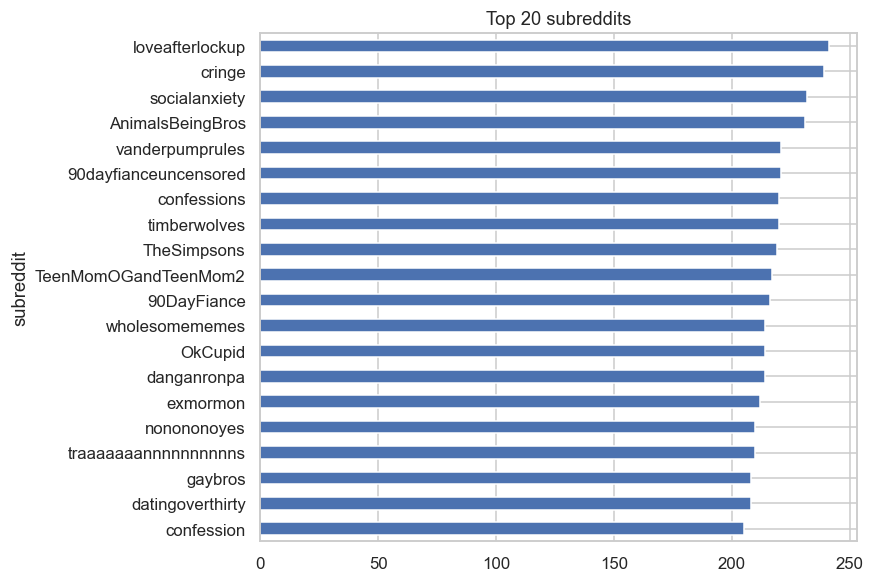

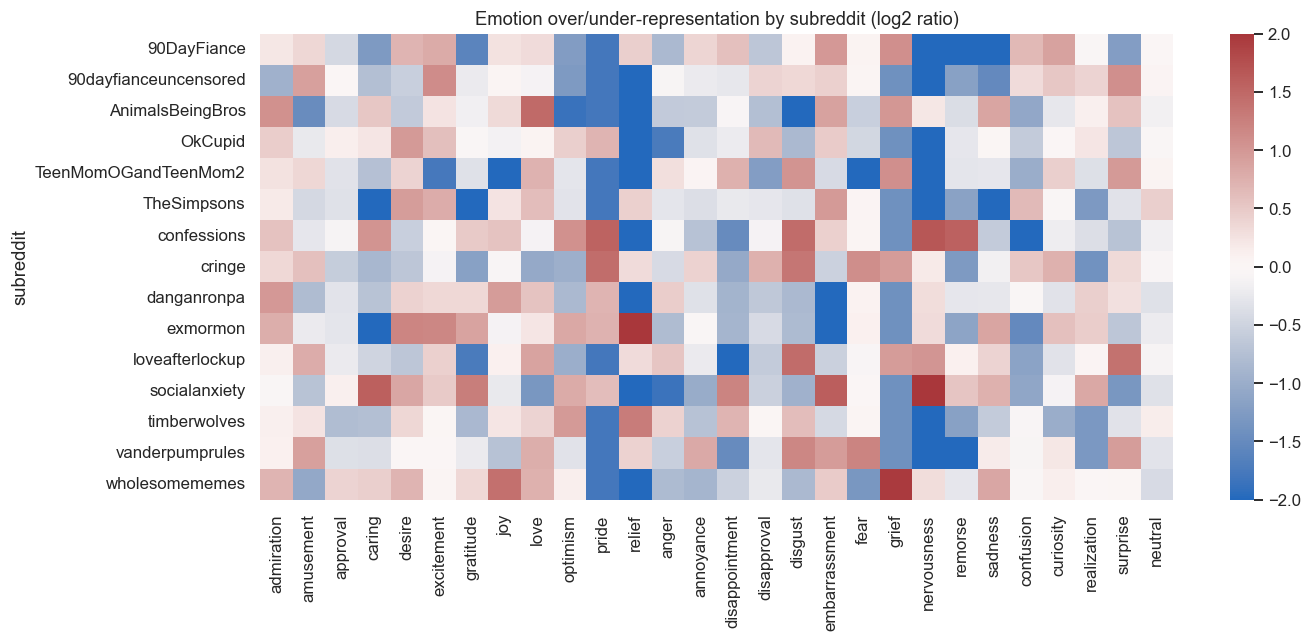

In [16]:
#. Metadata: subreddit, reply type, time, author, thread
sub = C.subreddit.value_counts()
print('subreddits:', len(sub), '| top-10 share:', f'{sub.head(10).sum() / len(C):.2%}')
sub.head(20).sort_values().plot.barh(figsize=(7, 6), title='Top 20 subreddits'); plt.show()
top_sub = sub.head(15).index
rate_sub = Y[C.subreddit.isin(top_sub)].groupby(C.subreddit).mean()
plt.figure(figsize=(13, 6))
sns.heatmap(np.log2((rate_sub + 1e-3) / (Y.mean() + 1e-3)), cmap='vlag', center=0, vmin=-2, vmax=2)
plt.title('Emotion over/under-representation by subreddit (log2 ratio)'); plt.tight_layout(); plt.show()


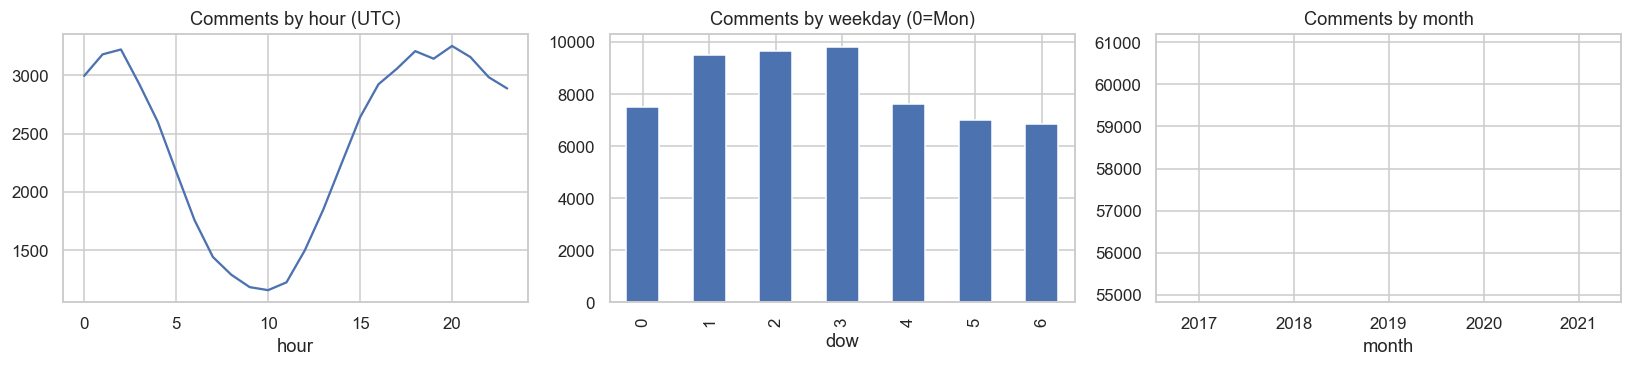

<Axes: xlabel='hour'>

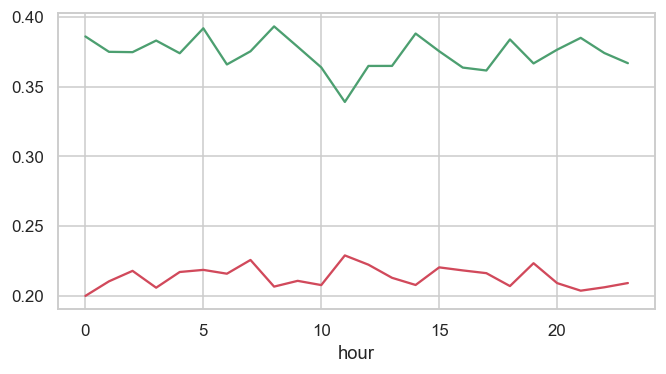

In [14]:
# time
C['hour'] = C.created_dt.dt.hour; C['dow'] = C.created_dt.dt.dayofweek; C['month'] = C.created_dt.dt.to_period('M')
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
C.groupby('hour').size().plot(ax=ax[0], title='Comments by hour (UTC)')
C.groupby('dow').size().plot.bar(ax=ax[1], title='Comments by weekday (0=Mon)')
C.groupby('month').size().plot(ax=ax[2], title='Comments by month')
plt.tight_layout(); plt.show()
pos_rate = Y[SENT['positive']].max(axis=1).groupby(C.hour).mean()
neg_rate = Y[SENT['negative']].max(axis=1).groupby(C.hour).mean()
plt.figure(figsize=(7, 3.5)); pos_rate.plot(label='positive', color=PAL['positive']); neg_rate.plot(label='negative', color=PAL['negative'])


In [19]:
# authors & threads
ac = C.author.value_counts()
print('authors:', len(ac), '| [deleted]:', int((C.author == '[deleted]').sum()),
      '| top-1% authors write', f'{ac.head(max(1, len(ac) // 100)).sum() / len(C):.1%}', 'of comments | max per author:', ac.iloc[0])
tc = C.link_id.value_counts()
print('threads:', len(tc), '| median comments/thread:', tc.median(), '| max:', tc.iloc[0])
print('Leakage risk -> random split puts same author/thread in train & test. Consider GroupKFold on link_id/author.')

authors: 49178 | [deleted]: 1063 | top-1% authors write 6.3% of comments | max per author: 1063
threads: 44897 | median comments/thread: 1.0 | max: 25
Leakage risk -> random split puts same author/thread in train & test. Consider GroupKFold on link_id/author.


                      ratings  avg_labels  neutral  support
example_very_unclear                                       
False                  207814       1.201    0.266    0.611
True                     3411       0.000    0.000      NaN
share of unclear ratings: 1.61%
             comments  no_majority   words
unclear_any                               
False           55278        0.056  12.985
True             2733        0.236  11.474


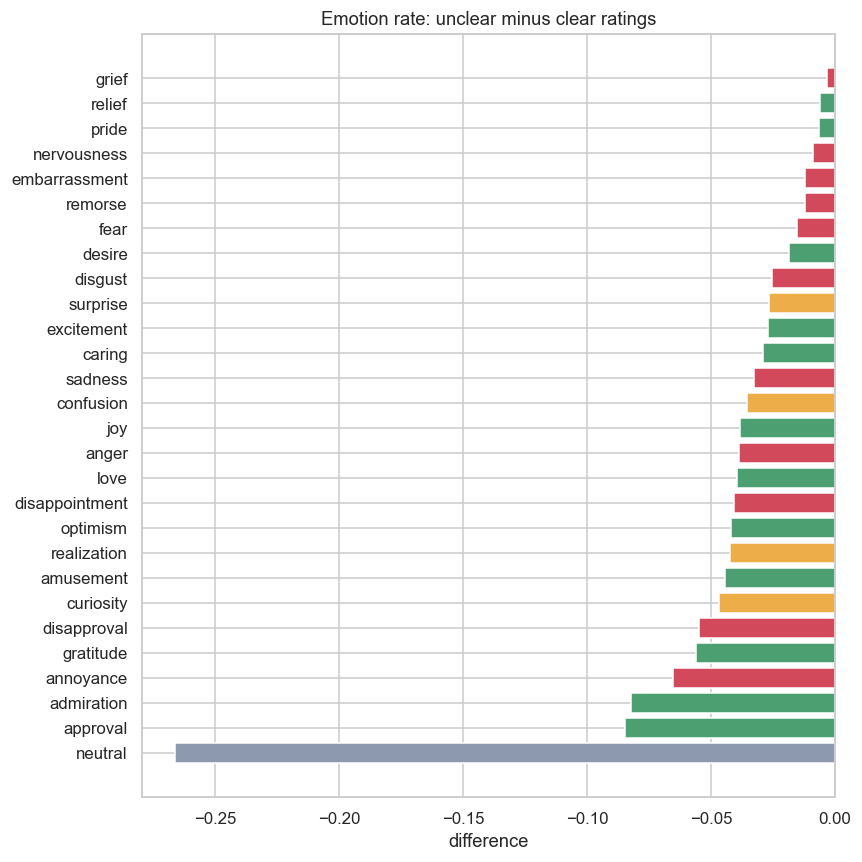

In [20]:
# %% 10. "Very unclear" examples
u = df.groupby('example_very_unclear').agg(ratings=('id', 'size'), avg_labels=('n_labels', 'mean'),
                                           neutral=('neutral', 'mean'), support=('label_support', 'mean'))
print(u.round(3))
print('share of unclear ratings:', f'{df.example_very_unclear.mean():.2%}')
C['unclear_any'] = C.unclear_frac > 0
print(C.groupby('unclear_any').agg(comments=('text', 'size'), no_majority=('n_major', lambda s: (s == 0).mean()),
                                   words=('n_words', 'mean')).round(3))
d = (df[df.example_very_unclear][emotions].mean() - df[~df.example_very_unclear][emotions].mean())
barh_emotions(d.sort_values(), 'Emotion rate: unclear minus clear ratings', 'difference')

Comment-level sentiment share (majority):
 maj_positive     0.375
maj_negative     0.213
maj_ambiguous    0.115
maj_neutral      0.306
dtype: float64
Comments with NO majority label: 6.46%
Any rater says positive AND any says negative on same comment: 20.77%


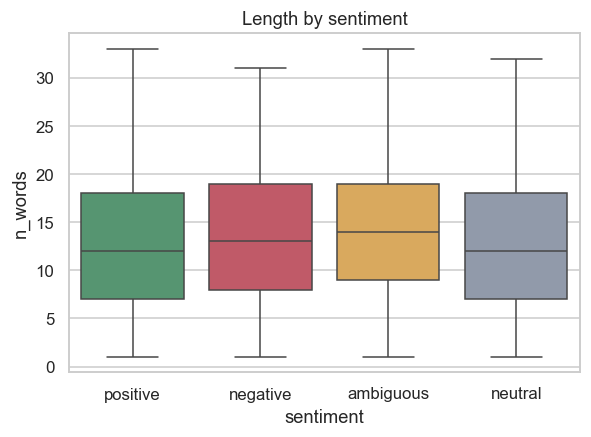

In [21]:
# %% 11. Sentiment-level view
for s in SENT:
    C[f'maj_{s}'] = Y[SENT[s]].max(axis=1)
C['vote_pos'] = votes[SENT['positive']].sum(axis=1) > 0
C['vote_neg'] = votes[SENT['negative']].sum(axis=1) > 0
print('Comment-level sentiment share (majority):\n', C[[f'maj_{s}' for s in SENT]].mean().round(3))
print('Comments with NO majority label:', f'{(C.n_major == 0).mean():.2%}')
print('Any rater says positive AND any says negative on same comment:', f'{(C.vote_pos & C.vote_neg).mean():.2%}')

sent_len = pd.concat([C.loc[C[f'maj_{s}'] == 1, ['n_words']].assign(sentiment=s) for s in SENT])
plt.figure(figsize=(6, 4)); sns.boxplot(data=sent_len, x='sentiment', y='n_words', showfliers=False, palette=PAL); plt.title('Length by sentiment'); plt.show()


In [22]:

# %% 12. Headline findings (auto-generated)
print('=' * 70)
print(f'Comments: {len(C):,} | ratings: {len(df):,} | raters: {df.rater_id.nunique()}')
print(f'Most common: {summary.index[0]} ({summary.comment_share.iloc[0]:.1%}), rarest: {summary.index[-1]} ({summary.comment_share.iloc[-1]:.2%})')
print(f'Imbalance ratio: {summary.comment_count.max() / summary.comment_count.min():.0f}x')
print(f'No-consensus comments: {(C.n_major == 0).mean():.1%}')
print(f'Best agreement: {psa.idxmax()} ({psa.max():.2f}) | worst: {psa.idxmin()} ({psa.min():.2f})')
if len(pairs):
    print(f'Strongest pair (lift): {pairs.iloc[0].a} + {pairs.iloc[0].b} (lift {pairs.iloc[0].lift:.1f})')
print(f'Median length: {C.n_words.median():.0f} words | [NAME] in {C.has_name.mean():.1%} of comments')
print(f'Top subreddit: {sub.index[0]} ({sub.iloc[0] / len(C):.1%}) | very-unclear ratings: {df.example_very_unclear.mean():.1%}')

Comments: 58,011 | ratings: 211,225 | raters: 82
Most common: neutral (30.6%), rarest: grief (0.17%)
Imbalance ratio: 185x
No-consensus comments: 6.5%
Best agreement: gratitude (0.68) | worst: pride (0.10)
Strongest pair (lift): remorse + sadness (lift 3.8)
Median length: 12 words | [NAME] in 13.8% of comments
Top subreddit: loveafterlockup (0.4%) | very-unclear ratings: 1.6%


In [18]:

emotion_cols = [
    'admiration',
    'amusement',
    'anger',
    'annoyance',
    'approval',
    'caring',
    'confusion',
    'curiosity',
    'desire',
    'disappointment',
    'disapproval',
    'disgust',
    'embarrassment',
    'excitement',
    'fear',
    'gratitude',
    'grief',
    'joy',
    'love',
    'nervousness',
    'optimism',
    'pride',
    'realization',
    'relief',
    'remorse',
    'sadness',
    'surprise',
    'neutral'
]
import re

df['char_count'] = df['text'].str.len()

df['word_count'] = df['text'].str.split().str.len()

df['sentence_count'] = df['text'].str.count(r'[.!?]') + 1

df['punctuation_count'] = df['text'].str.count(r'[^\w\s]')

df['uppercase_count'] = df['text'].str.count(r'[A-Z]')

df['exclamation_count'] = df['text'].str.count('!')

df['question_count'] = df['text'].str.count(r'\?')

df[['char_count',
    'word_count',
    'sentence_count',
    'punctuation_count',
    'uppercase_count',
    'exclamation_count',
    'question_count']].describe()
emotion_text_stats = []

for emotion in emotion_cols:
    subset = df[df[emotion] == 1]

    emotion_text_stats.append({
        'emotion': emotion,
        'samples': len(subset),
        'avg_words': subset['word_count'].mean(),
        'median_words': subset['word_count'].median(),
        'avg_chars': subset['char_count'].mean(),
        'avg_punctuation': subset['punctuation_count'].mean(),
        'avg_exclamation': subset['exclamation_count'].mean(),
        'avg_question': subset['question_count'].mean()
    })

emotion_text_stats = pd.DataFrame(emotion_text_stats)

emotion_text_stats

,emotion,samples,avg_words,median_words,avg_chars,avg_punctuation,avg_exclamation,avg_question
0,admiration,17131,12.259238,12.0,65.911447,2.994513,0.346915,0.053237
1,amusement,9245,12.730124,12.0,66.795890,2.835587,0.207896,0.085019
2,anger,8084,12.639782,12.0,68.293914,2.952375,0.213137,0.139906
3,annoyance,13618,14.089514,14.0,76.214569,3.081803,0.140402,0.114261
4,approval,17620,13.817991,14.0,73.658513,3.069523,0.180533,0.050454
5,caring,5999,14.290882,14.0,75.215703,3.140857,0.228871,0.051842
6,confusion,7359,14.389591,14.0,76.120533,3.320968,0.106129,0.562169
7,curiosity,9692,13.499071,13.0,71.834090,3.214610,0.133512,0.818407
8,desire,3817,14.788839,15.0,75.299712,2.949175,0.217448,0.053707
9,disappointment,8469,14.564175,14.0,77.870587,3.127524,0.113000,0.072854


# OBSERVATIONS
1. (cuorisity,confusion)wale emotion me avg question bahut jyada h
2. Realization and optimism labels are associated with longer average texts in the analyzed dataset.
3. Gratitude has the lowest average text length among the 28 emotion labels.
4.  Curiosity and confusion show relatively high average question-mark counts, with curiosity having the highest value.
5. Excitement has the highest average exclamation-mark count, suggesting that expressive punctuation may provide useful linguistic information.
6. Total punctuation count shows less separation across emotions than some specific punctuation features.
7. Emotion-wise sample imbalance means that findings for rare emotions, particularly grief, should be interpreted cautiously.

neutral           55298
approval          17620
admiration        17131
annoyance         13618
gratitude         11625
disapproval       11424
curiosity          9692
amusement          9245
realization        8785
optimism           8715
disappointment     8469
love               8191
anger              8084
joy                7983
confusion          7359
sadness            6758
caring             5999
excitement         5629
surprise           5514
disgust            5301
desire             3817
fear               3197
remorse            2525
embarrassment      2476
nervousness        1810
pride              1302
relief             1289
grief               673
dtype: int64
neutral           26.179666
approval           8.341816
admiration         8.110309
annoyance          6.447154
gratitude          5.503610
disapproval        5.408451
curiosity          4.588472
amusement          4.376849
realization        4.159072
optimism           4.125932
disappointment     4.009469
love   

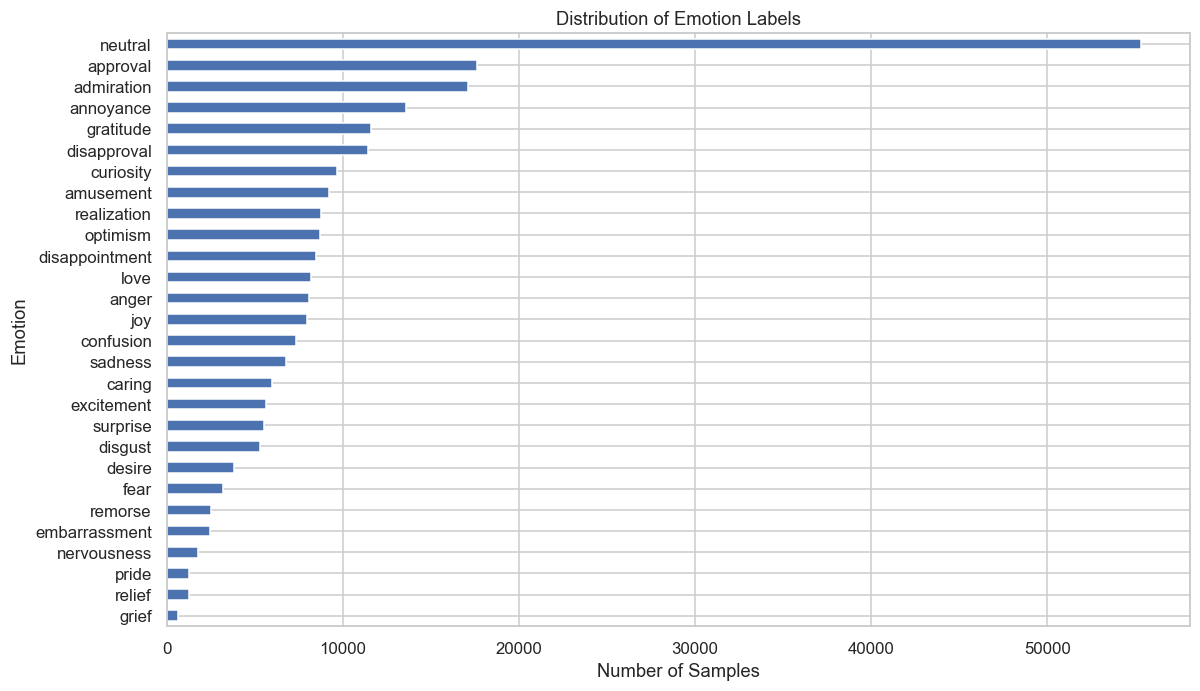

In [21]:
emotion_counts = df[emotion_cols].sum().sort_values(ascending=False)

print(emotion_counts)
emotion_percentage = (
    df[emotion_cols].mean() * 100
).sort_values(ascending=False)

print(emotion_percentage)
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

emotion_counts.sort_values().plot(kind='barh')

plt.title("Distribution of Emotion Labels")
plt.xlabel("Number of Samples")
plt.ylabel("Emotion")

plt.show()

# AFTER APPLYING N-grams


In [22]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer



emotion_cols = [
    'admiration', 'amusement', 'anger', 'annoyance',
    'approval', 'caring', 'confusion', 'curiosity',
    'desire', 'disappointment', 'disapproval', 'disgust',
    'embarrassment', 'excitement', 'fear', 'gratitude',
    'grief', 'joy', 'love', 'nervousness', 'optimism',
    'pride', 'realization', 'relief', 'remorse',
    'sadness', 'surprise', 'neutral'
]


df['text'] = df['text'].fillna('').astype(str)



def get_ngrams(texts, ngram_range=(2, 3), top_n=20):

    vectorizer = CountVectorizer(
        ngram_range=ngram_range,
        stop_words='english',
        min_df=2
    )

    X = vectorizer.fit_transform(texts)

    ngrams = vectorizer.get_feature_names_out()
    counts = X.sum(axis=0).A1

    result = pd.DataFrame({
        'ngram': ngrams,
        'count': counts
    })

    result = result.sort_values(
        by='count',
        ascending=False
    ).head(top_n)

    return result



emotion_ngram_results = {}

for emotion in emotion_cols:

    print("\n" + "=" * 60)
    print("EMOTION:", emotion.upper())
    print("=" * 60)

    emotion_texts = df.loc[
        df[emotion] == 1,
        'text'
    ]

    
    result = get_ngrams(
        emotion_texts,
        ngram_range=(2, 3),
        top_n=20
    )

    emotion_ngram_results[emotion] = result

    print(result)




print("\nTop Gratitude N-grams:")
print(emotion_ngram_results['gratitude'])

print("\nTop Anger N-grams:")
print(emotion_ngram_results['anger'])

print("\nTop Joy N-grams:")
print(emotion_ngram_results['joy'])




with pd.ExcelWriter("goemotions_ngrams.xlsx") as writer:

    for emotion, result in emotion_ngram_results.items():
        result.to_excel(
            writer,
            sheet_name=emotion,
            index=False
        )

print("\nN-gram analysis completed!")
print("Results saved to: goemotions_ngrams.xlsx")


EMOTION: ADMIRATION
                   ngram  count
21988         looks like    161
13768           good job    143
37601            ve seen    131
13860          good luck    110
28396        pretty good     95
32985        sounds like     92
29648        really good     84
28311        pretty cool     75
9286            don know     58
29716        really like     54
25295           nice try     54
14888         great idea     53
14917          great job     48
13747          good idea     47
20626         like great     47
35266     thanks sharing     46
14164         good thing     46
7861           damn good     44
22040       looks pretty     42
29536  really appreciate     40

EMOTION: AMUSEMENT
               ngram  count
14285     looks like     62
13586       lol just     52
8607           ha ha     51
20614    sounds like     51
4930        don know     46
23594        ve seen     44
6287       feel like     39
13488       lol good     31
17801   pretty funny     30
13671  

# observations
# most important


## These are the words those are repeatedly come together
# after applying n-grams
| Emotion | Strong recurring patterns | What it suggests |
|---|---|---|
| **Admiration** | `good job`, `good luck`, `really good`, `pretty cool`, `great idea`, `really appreciate` | Praise, appreciation and positive evaluation |
| **Amusement** | `lol just`, `kinda funny`, `thought funny`, `makes laugh`, `haha just` | Humour, laughter and entertainment |
| **Anger** | `hate people`, `holy shit`, `oh fuck`, `just shut`, `fucking hate`, `fucking idiot` | Hostility, profanity, criticism and aggression |
| **Annoyance** | `don care`, `don want`, `holy shit`, `piece shit`, `don understand` | Frustration, irritation and negative reaction |
| **Approval** | `good luck`, `makes sense`, `pretty sure`, `completely agree`, `make sure` | Agreement, acceptance and positive evaluation |
| **Caring** | `don worry`, `stay strong`, `feel better`, `stay safe`, `sorry hear`, `wish best` | Concern, support, sympathy and encouragement |
| **Confusion** | `don know`, `don understand`, `don think`, `maybe just`, `wasn sure`, `does mean` | Uncertainty, lack of understanding and questioning |
| **Curiosity** | `just curious`, `want know`, `did say`, `genuinely curious`, `does know` | Information seeking and questioning |
| **Desire** | `just want`, `really hope`, `just wish`, `really want`, `ve wanted` | Wants, wishes and aspirations |
| **Disappointment** | `feel bad`, `really disappointed`, `just bad`, `really bad`, `bad luck` | Negative outcome and dissatisfaction |
| **Disapproval** | `don think`, `don want`, `don like`, `don believe`, `doesn mean` | Rejection, disagreement and criticism |
| **Disgust** | `just awful`, `god awful`, `really bad`, `truly disgusting`, `really weird` | Strong negative evaluation and aversion |
| **Embarrassment** | `awkward moment`, `embarrassed admit`, `actually embarrassing`, `admit shocked` | Social awkwardness and self-consciousness |
| **Excitement** | `cake day`, `happy cake day`, `happy new year`, `happy birthday`, `hell yeah` | Celebration, enthusiasm and positive arousal |
| **Fear** | `panic attack`, `horror movie`, `terrible idea`, `inside terrifying`, `afraid ask` | Fear, threat and anxiety-related situations |
| **Gratitude** | `thanks sharing`, `thanks info`, `thanks advice`, `kind words`, `really appreciate` | Explicit thanking and appreciation |
| **Grief** | `sorry loss`, `rest peace`, `condolences loss`, `actually dead`, `crying crying` | Bereavement, death and mourning |
| **Joy** | `cake day`, `makes happy`, `happy birthday`, `glad hear`, `im glad` | Happiness, celebration and positive events |
| **Love** | `gotta love`, `really love`, `just love`, `love people`, `love game` | Affection and strong positive attachment |
| **Nervousness** | `square nervous`, `time square nervous`, `know little`, `actively trying` | Situational nervousness and uncertainty |
| **Optimism** | `good luck`, `really hope`, `just hope`, `hope gets`, `hope works` | Hope, positive expectation and future orientation |
| **Pride** | `good job`, `did good`, `happy proud`, `accomplishment proud`, `just won` | Achievement and accomplishment |
| **Realization** | `didn realize`, `just realized`, `did know`, `makes sense` | Discovery, understanding and new awareness |
| **Relief** | `feel better`, `thank god`, `don worry`, `glad wasn`, `just glad` | Positive outcome after concern/problem |
| **Remorse** | `oh sorry`, `im sorry`, `feel sorry`, `sorry happened`, `sorry wrong` | Apology, regret and feeling sorry |
| **Sadness** | `feel bad`, `sorry loss`, `makes sad`, `just sad`, `painful watch` | Sadness, loss and emotional pain |
| **Surprise** | `oh god`, `wow really`, `oh wow`, `wouldn surprised`, `just wow` | Shock, unexpectedness and astonishment |
| **Neutral** | `looks like`, `don know`, `don think`, `feel like`, `sounds like` | General conversational/informational language |